# Personal Finance and Expense Analysis Using Python and Power BI

---

### Section 1: Project Introduction

#### 1.1 Project Title
**Personal Finance and Expense Analysis Using Python and Power BI**

#### 1.2 Project Objective
The primary objective of this project is to perform comprehensive end-to-end data analytics on personal income, expenses, savings patterns, and budget variances. By applying descriptive analytics, trend modeling, and visual storytelling, the project helps uncover financial habits, pinpoint budget overflows, evaluate savings rates, and empower sound personal financial planning.

#### 1.3 Problem Statement
Individuals often find it challenging to track multi-channel spending across digital payment mechanisms (UPI, credit cards, debit cards, cash, net banking). Without structured monitoring, discretionary expenditures go unnoticed, savings targets are missed, and planned budgets are consistently breached. A centralized analytical workflow is essential to provide actionable visibility into cash flows.

#### 1.4 Project Scope
- Ingest and audit synthetic personal financial transactions spanning January 2026 to December 2026.
- Perform rigorous data cleaning, validation, and type conversions.
- Conduct exploratory data analysis (EDA) to compute key performance indicators (KPIs) including Total Income, Total Expenses, Net Savings, and Savings Rate.
- Generate and export high-resolution publication-quality visual charts for reporting.
- Evaluate budget performance by analyzing planned allocations versus actual expenditures.
- Formulate data-driven financial insights and strategic optimization recommendations.

#### 1.5 Technologies Used
- **Python 3.10+**: Core programming environment.
- **Pandas**: Structured tabular data manipulation and aggregation.
- **NumPy**: Numerical operations and vector calculations.
- **Matplotlib & Seaborn**: Statistical charting, customized visualization, and publication exports.
- **Jupyter Notebook**: Interactive computational notebook.
- **Power BI Desktop**: Business intelligence dashboarding, interactive data modeling, and DAX measures.


---
### Section 2: Import Libraries
In this step, we import standard Python libraries for data processing, statistical computing, and data visualization. We also configure presentation aesthetics for consistent, publication-ready charts.


In [1]:
# Standard library imports
import os
import warnings
warnings.filterwarnings('ignore')

# Data handling and computation
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting settings
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Ensure output directory for charts exists
os.makedirs('../Charts', exist_ok=True)
print("Libraries imported successfully. Matplotlib style configured.")


Libraries imported successfully. Matplotlib style configured.


---
### Section 3: Load Dataset
We read the raw CSV files (`transactions.csv` and `monthly_budget.csv`) using Pandas, inspect their shapes, column structures, and inspect sample records.


In [2]:
# Define relative dataset file paths
transactions_path = '../Dataset/transactions.csv'
budget_path = '../Dataset/monthly_budget.csv'

# Load CSV datasets into Pandas DataFrames
df_transactions = pd.read_csv(transactions_path)
df_budget = pd.read_csv(budget_path)

print(f"Transactions Dataset Loaded: {df_transactions.shape[0]} rows, {df_transactions.shape[1]} columns")
print(f"Monthly Budget Dataset Loaded: {df_budget.shape[0]} rows, {df_budget.shape[1]} columns")


Transactions Dataset Loaded: 364 rows, 10 columns
Monthly Budget Dataset Loaded: 156 rows, 3 columns


In [3]:
# Display the first 10 records of transactions
print("--- First 10 Transactions ---")
df_transactions.head(10)


--- First 10 Transactions ---


,Transaction_ID,Date,Description,Category,Type,Amount,Payment_Method,Account_Type,Month,Year
0,TXN00001,2026-01-03,Monthly Corporate Salary Credit,Salary,Income,80000.00,Net Banking,Salary Account,January,2026
1,TXN00002,2026-01-04,Dining at Restaurant / Swiggy / Zomato order,Food,Expense,388.44,Debit Card,Salary Account,January,2026
2,TXN00003,2026-01-05,Apartment Monthly Rent,Rent,Expense,20000.00,Net Banking,Salary Account,January,2026
3,TXN00004,2026-01-05,Household repairs / Laundry / Miscellaneous,Other Expenses,Expense,935.71,Cash,Cash Wallet,January,2026
4,TXN00005,2026-01-07,"Clothing, footwear & personal gear",Shopping,Expense,7401.90,Debit Card,Salary Account,January,2026
5,TXN00006,2026-01-08,Flight/Train tickets & weekend getaway stays,Travel,Expense,10808.10,Net Banking,Salary Account,January,2026
6,TXN00007,2026-01-09,High-Speed Broadband Subscription,Internet,Expense,1199.00,UPI,Salary Account,January,2026
7,TXN00008,2026-01-10,Metro card recharge / Auto / Fuel filling,Transportation,Expense,1385.89,UPI,Savings Account,January,2026
8,TXN00009,2026-01-10,Car Loan EMI Auto-debit,EMI,Expense,10500.00,Net Banking,Salary Account,January,2026
9,TXN00010,2026-01-11,Dining at Restaurant / Swiggy / Zomato order,Food,Expense,1397.20,UPI,Salary Account,January,2026


In [4]:
# Display column names and data types
print("--- Transactions Dataset Information ---")
df_transactions.info()


--- Transactions Dataset Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 364 entries, 0 to 363
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Transaction_ID  364 non-null    object 
 1   Date            364 non-null    object 
 2   Description     364 non-null    object 
 3   Category        364 non-null    object 
 4   Type            364 non-null    object 
 5   Amount          364 non-null    float64
 6   Payment_Method  364 non-null    object 
 7   Account_Type    364 non-null    object 
 8   Month           364 non-null    object 
 9   Year            364 non-null    int64  
dtypes: float64(1), int64(1), object(8)
memory usage: 28.6+ KB


In [5]:
# Display first 5 records and info of monthly budget
print("--- First 5 Monthly Budget Records ---")
display(df_budget.head(5))
df_budget.info()


--- First 5 Monthly Budget Records ---


,Month,Category,Budget_Amount
0,January,Food,9000.0
1,January,Rent,20000.0
2,January,Transportation,6000.0
3,January,Shopping,7000.0
4,January,Electricity,2500.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 3 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Month          156 non-null    object 
 1   Category       156 non-null    object 
 2   Budget_Amount  156 non-null    float64
dtypes: float64(1), object(2)
memory usage: 3.8+ KB


---
### Section 4: Data Cleaning and Validation
Data quality is paramount for accurate financial accounting. Here, we:
1. Check for missing (null) values.
2. Verify uniqueness of transaction IDs and identify duplicates.
3. Convert the `Date` column into proper datetime format.
4. Validate transaction amounts (ensure positive non-zero numbers).
5. Verify valid category and type assignments.
6. Create derived temporal features if needed.


In [6]:
# 1. Missing Values Check
print("--- Missing Values in Transactions ---")
print(df_transactions.isnull().sum())

print("\n--- Missing Values in Monthly Budget ---")
print(df_budget.isnull().sum())


--- Missing Values in Transactions ---
Transaction_ID    0
Date              0
Description       0
Category          0
Type              0
Amount            0
Payment_Method    0
Account_Type      0
Month             0
Year              0
dtype: int64

--- Missing Values in Monthly Budget ---
Month            0
Category         0
Budget_Amount    0
dtype: int64


In [7]:
# 2. Duplicate Records Check
dup_txn_ids = df_transactions['Transaction_ID'].duplicated().sum()
total_dups = df_transactions.duplicated().sum()
print(f"Duplicate Transaction IDs: {dup_txn_ids}")
print(f"Exact Duplicate Rows: {total_dups}")


Duplicate Transaction IDs: 0
Exact Duplicate Rows: 0


In [8]:
# 3. Datetime Conversion and Temporal Sorting
df_transactions['Date'] = pd.to_datetime(df_transactions['Date'], format='%Y-%m-%d')
df_transactions = df_transactions.sort_values('Date').reset_index(drop=True)

# 4. Amount Validation
negative_or_zero = (df_transactions['Amount'] <= 0).sum()
print(f"Number of invalid amounts (<= 0): {negative_or_zero}")

# 5. Categorical Validation
valid_types = ['Income', 'Expense']
invalid_types = df_transactions[~df_transactions['Type'].isin(valid_types)]
print(f"Invalid Transaction Types Count: {len(invalid_types)}")

# 6. Extract Month-Year for chronological aggregation
df_transactions['Month_Num'] = df_transactions['Date'].dt.month
df_transactions['MonthYear'] = df_transactions['Date'].dt.strftime('%Y-%m')

print("\nData Cleaning and Validation complete. Summary Statistics:")
df_transactions.describe()


Number of invalid amounts (<= 0): 0
Invalid Transaction Types Count: 0

Data Cleaning and Validation complete. Summary Statistics:


,Date,Amount,Year,Month_Num
count,364,364.000000,364.0,364.000000
mean,2026-07-03 23:24:23.736263680,6199.564038,2026.0,6.629121
min,2026-01-03 00:00:00,182.230000,2026.0,1.000000
25%,2026-03-30 12:00:00,1074.312500,2026.0,3.000000
50%,2026-07-05 00:00:00,1755.060000,2026.0,7.000000
75%,2026-10-10 00:00:00,3889.877500,2026.0,10.000000
max,2026-12-30 00:00:00,80000.000000,2026.0,12.000000
std,NaN,14452.138780,0.0,3.553189


---
### Section 5: Exploratory Data Analysis (EDA)
In this section, we compute essential personal finance KPIs and aggregates:
- Total Income, Total Expenses, and Net Savings
- Overall Savings Rate (%)
- Average Monthly Expenses
- Category-wise Spending Breakdown
- Payment Method Distribution
- Monthly Cash Flow Aggregation


In [9]:
# 5.1 Financial Core KPIs
total_income = df_transactions[df_transactions['Type'] == 'Income']['Amount'].sum()
total_expenses = df_transactions[df_transactions['Type'] == 'Expense']['Amount'].sum()
net_savings = total_income - total_expenses
savings_rate = (net_savings / total_income) * 100
avg_monthly_expenses = total_expenses / 12

print("==================================================")
print("              ANNUAL FINANCIAL KPIs (INR)         ")
print("==================================================")
print(f"Total Annual Income       : ₹ {total_income:,.2f}")
print(f"Total Annual Expenses     : ₹ {total_expenses:,.2f}")
print(f"Total Net Savings         : ₹ {net_savings:,.2f}")
print(f"Overall Savings Rate      : {savings_rate:.2f}%")
print(f"Average Monthly Expenses  : ₹ {avg_monthly_expenses:,.2f}")
print("==================================================")


              ANNUAL FINANCIAL KPIs (INR)         
Total Annual Income       : ₹ 1,176,600.00
Total Annual Expenses     : ₹ 1,080,041.31
Total Net Savings         : ₹ 96,558.69
Overall Savings Rate      : 8.21%
Average Monthly Expenses  : ₹ 90,003.44


In [10]:
# 5.2 Category-Wise Expense Aggregation
df_expenses = df_transactions[df_transactions['Type'] == 'Expense']
category_summary = df_expenses.groupby('Category')['Amount'].agg(
    Total_Spent='sum',
    Transaction_Count='count',
    Average_Ticket='mean'
).sort_values('Total_Spent', ascending=False)

category_summary['Percentage_of_Total'] = (category_summary['Total_Spent'] / total_expenses) * 100

highest_category = category_summary.index[0]
highest_cat_amt = category_summary.loc[highest_category, 'Total_Spent']
lowest_category = category_summary.index[-1]
lowest_cat_amt = category_summary.loc[lowest_category, 'Total_Spent']

print(f"Highest Spending Category : {highest_category} (₹ {highest_cat_amt:,.2f} - {category_summary.loc[highest_category, 'Percentage_of_Total']:.2f}%)")
print(f"Lowest Spending Category  : {lowest_category} (₹ {lowest_cat_amt:,.2f} - {category_summary.loc[lowest_category, 'Percentage_of_Total']:.2f}%)")
print("\n--- Category-Wise Expense Breakdown ---")
display(category_summary.style.format({
    'Total_Spent': '₹ {:,.2f}',
    'Average_Ticket': '₹ {:,.2f}',
    'Percentage_of_Total': '{:.2f}%'
}))


Highest Spending Category : Rent (₹ 240,000.00 - 22.22%)
Lowest Spending Category  : Internet (₹ 14,388.00 - 1.33%)

--- Category-Wise Expense Breakdown ---


,Total_Spent,Transaction_Count,Average_Ticket,Percentage_of_Total
Category,,,,
Rent,"₹ 240,000.00",12,"₹ 20,000.00",22.22%
Shopping,"₹ 147,618.35",28,"₹ 5,272.08",13.67%
Travel,"₹ 143,189.56",14,"₹ 10,227.83",13.26%
EMI,"₹ 126,000.00",12,"₹ 10,500.00",11.67%
Groceries,"₹ 122,955.76",45,"₹ 2,732.35",11.38%
Food,"₹ 76,958.52",65,"₹ 1,183.98",7.13%
Transportation,"₹ 53,888.03",50,"₹ 1,077.76",4.99%
Entertainment,"₹ 45,432.64",30,"₹ 1,514.42",4.21%
Electricity,"₹ 31,200.00",12,"₹ 2,600.00",2.89%


In [11]:
# 5.3 Monthly Cash Flow Aggregation (Income, Expenses, Savings)
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 
               'July', 'August', 'September', 'October', 'November', 'December']

monthly_summary = df_transactions.pivot_table(
    index='Month',
    columns='Type',
    values='Amount',
    aggfunc='sum',
    fill_value=0.0
).reindex(month_order)

monthly_summary['Savings'] = monthly_summary['Income'] - monthly_summary['Expense']
monthly_summary['Savings_Rate_%'] = (monthly_summary['Savings'] / monthly_summary['Income']) * 100

max_exp_month = monthly_summary['Expense'].idxmax()
min_exp_month = monthly_summary['Expense'].idxmin()
max_sav_month = monthly_summary['Savings'].idxmax()

print(f"Month with Highest Expenses : {max_exp_month} (₹ {monthly_summary.loc[max_exp_month, 'Expense']:,.2f})")
print(f"Month with Lowest Expenses  : {min_exp_month} (₹ {monthly_summary.loc[min_exp_month, 'Expense']:,.2f})")
print(f"Month with Highest Savings  : {max_sav_month} (₹ {monthly_summary.loc[max_sav_month, 'Savings']:,.2f})")
print("\n--- Monthly Cash Flow Summary ---")
display(monthly_summary.style.format({
    'Income': '₹ {:,.2f}',
    'Expense': '₹ {:,.2f}',
    'Savings': '₹ {:,.2f}',
    'Savings_Rate_%': '{:.2f}%'
}))


Month with Highest Expenses : June (₹ 114,185.14)
Month with Lowest Expenses  : July (₹ 58,501.02)
Month with Highest Savings  : July (₹ 48,498.98)

--- Monthly Cash Flow Summary ---


Type,Expense,Income,Savings,Savings_Rate_%
Month,,,,
January,"₹ 87,409.14","₹ 92,000.00","₹ 4,590.86",4.99%
February,"₹ 111,766.35","₹ 111,000.00",₹ -766.35,-0.69%
March,"₹ 63,937.21","₹ 97,100.00","₹ 33,162.79",34.15%
April,"₹ 80,200.64","₹ 80,000.00",₹ -200.64,-0.25%
May,"₹ 83,428.05","₹ 92,000.00","₹ 8,571.95",9.32%
June,"₹ 114,185.14","₹ 110,300.00","₹ -3,885.14",-3.52%
July,"₹ 58,501.02","₹ 107,000.00","₹ 48,498.98",45.33%
August,"₹ 95,726.48","₹ 95,000.00",₹ -726.48,-0.76%
September,"₹ 95,036.56","₹ 84,600.00","₹ -10,436.56",-12.34%


In [12]:
# 5.4 Payment Method Distribution
payment_summary = df_expenses.groupby('Payment_Method')['Amount'].agg(
    Total_Spent='sum',
    Tx_Count='count'
).sort_values('Total_Spent', ascending=False)

payment_summary['Percentage'] = (payment_summary['Total_Spent'] / total_expenses) * 100
most_used_pm = payment_summary.index[0]

print(f"Most Utilized Payment Method by Volume: {most_used_pm} ({payment_summary.loc[most_used_pm, 'Percentage']:.2f}% of expenses)")
print("\n--- Payment Method Distribution ---")
display(payment_summary.style.format({
    'Total_Spent': '₹ {:,.2f}',
    'Percentage': '{:.2f}%'
}))


Most Utilized Payment Method by Volume: Net Banking (45.93% of expenses)

--- Payment Method Distribution ---


,Total_Spent,Tx_Count,Percentage
Payment_Method,,,
Net Banking,"₹ 496,026.37",44,45.93%
UPI,"₹ 240,537.83",126,22.27%
Credit Card,"₹ 158,475.18",73,14.67%
Debit Card,"₹ 142,991.38",55,13.24%
Cash,"₹ 42,010.55",37,3.89%


In [13]:
# 5.5 Budget vs Actual Variance Computation
# Aggregate actual expenses by Month and Category
actual_cat_month = df_expenses.groupby(['Month', 'Category'])['Amount'].sum().reset_index()
actual_cat_month.rename(columns={'Amount': 'Actual_Amount'}, inplace=True)

# Merge with monthly_budget
df_budget_vs_actual = pd.merge(df_budget, actual_cat_month, on=['Month', 'Category'], how='left')
df_budget_vs_actual['Actual_Amount'] = df_budget_vs_actual['Actual_Amount'].fillna(0.0)
df_budget_vs_actual['Variance'] = df_budget_vs_actual['Budget_Amount'] - df_budget_vs_actual['Actual_Amount']
df_budget_vs_actual['Status'] = np.where(df_budget_vs_actual['Variance'] >= 0, 'Within Budget', 'Over Budget')

total_budget = df_budget_vs_actual['Budget_Amount'].sum()
total_actual_on_budget = df_budget_vs_actual['Actual_Amount'].sum()
net_variance = total_budget - total_actual_on_budget

print(f"Total Budgeted Allocation : ₹ {total_budget:,.2f}")
print(f"Total Actual Expenditure  : ₹ {total_actual_on_budget:,.2f}")
print(f"Net Budget Variance       : ₹ {net_variance:,.2f} ({'Under Budget (Savings)' if net_variance >= 0 else 'Deficit'})")


Total Budgeted Allocation : ₹ 1,031,400.00
Total Actual Expenditure  : ₹ 1,080,041.31
Net Budget Variance       : ₹ -48,641.31 (Deficit)


---
### Section 6: Data Visualization
In this section, we generate 7 distinct visual analytics charts with titles, annotations, formatted axes, and clear color coding. Every figure is exported to the `../Charts/` folder as a PNG image:
1. **Monthly Income vs Expenses** (Dual Line Chart)
2. **Category-wise Expenses** (Donut Chart)
3. **Monthly Expense Trends** (Bar Chart)
4. **Monthly Savings Analysis** (Line Chart with Benchmark Line)
5. **Payment Method Analysis** (Bar Chart)
6. **Budget vs Actual Expenses** (Grouped Bar Chart)
7. **Expense Category Correlation** (Monthly Spending Correlation Heatmap)


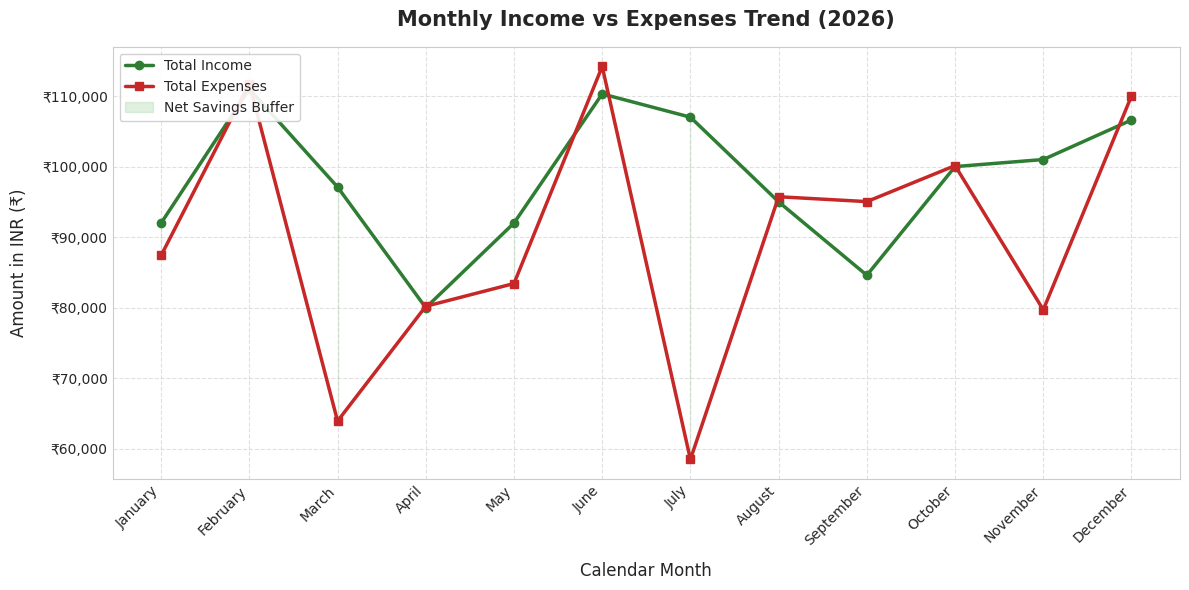

Chart 1 saved to: ../Charts/monthly_income_vs_expenses.png


In [14]:
# Chart 1: Monthly Income vs Expenses (Line Chart)
plt.figure(figsize=(12, 6))
x_months = monthly_summary.index

plt.plot(x_months, monthly_summary['Income'], marker='o', linewidth=2.5, color='#2e7d32', label='Total Income')
plt.plot(x_months, monthly_summary['Expense'], marker='s', linewidth=2.5, color='#c62828', label='Total Expenses')

# Fill area between curves to highlight savings
plt.fill_between(x_months, monthly_summary['Income'], monthly_summary['Expense'], 
                 where=(monthly_summary['Income'] >= monthly_summary['Expense']),
                 color='#a5d6a7', alpha=0.35, label='Net Savings Buffer')

plt.title('Monthly Income vs Expenses Trend (2026)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Calendar Month', fontsize=12, labelpad=10)
plt.ylabel('Amount in INR (₹)', fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right')
plt.gca().yaxis.set_major_formatter('₹{:,.0f}'.format)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper left')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

chart1_path = '../Charts/monthly_income_vs_expenses.png'
plt.savefig(chart1_path, dpi=300)
plt.show()
print(f"Chart 1 saved to: {chart1_path}")


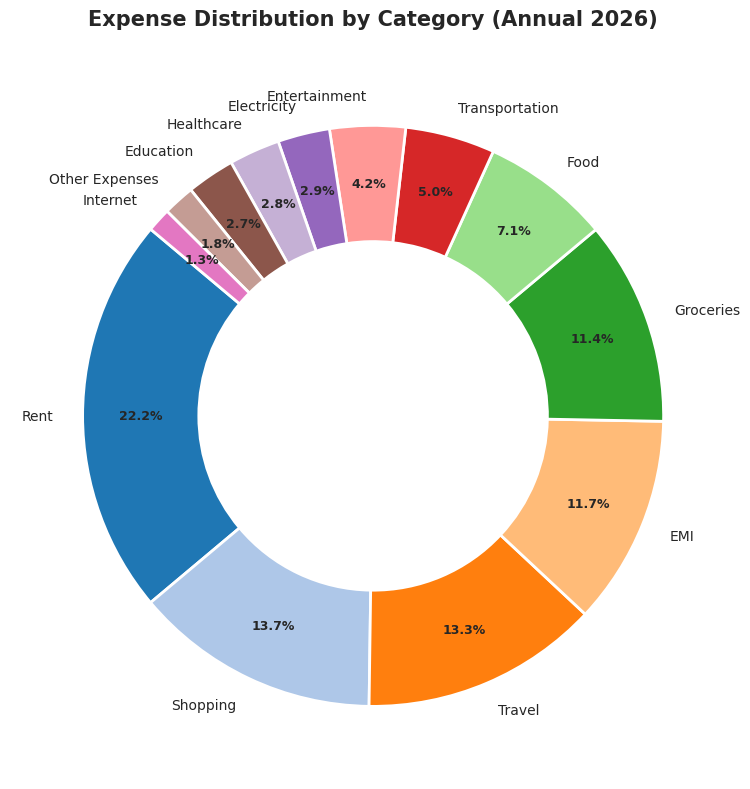

Chart 2 saved to: ../Charts/category_wise_expenses.png


In [15]:
# Chart 2: Category-wise Expenses (Donut Chart)
plt.figure(figsize=(10, 8))
cat_data = category_summary['Total_Spent']
colors = sns.color_palette('tab20', n_colors=len(cat_data))

wedges, texts, autotexts = plt.pie(
    cat_data,
    labels=cat_data.index,
    autopct='%1.1f%%',
    pctdistance=0.8,
    startangle=140,
    colors=colors,
    wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2)
)

for autotext in autotexts:
    autotext.set_fontsize(9)
    autotext.set_weight('bold')

plt.title('Expense Distribution by Category (Annual 2026)', fontsize=15, fontweight='bold', pad=20)
plt.tight_layout()

chart2_path = '../Charts/category_wise_expenses.png'
plt.savefig(chart2_path, dpi=300)
plt.show()
print(f"Chart 2 saved to: {chart2_path}")


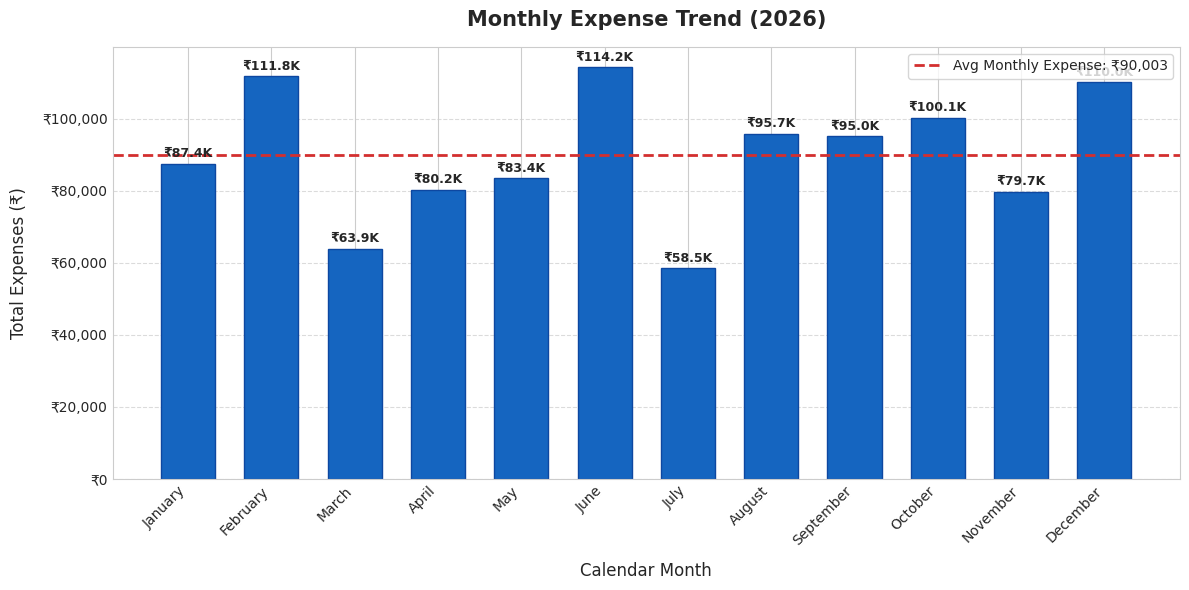

Chart 3 saved to: ../Charts/monthly_expense_trend.png


In [16]:
# Chart 3: Monthly Expense Trends (Bar Chart)
plt.figure(figsize=(12, 6))
bars = plt.bar(monthly_summary.index, monthly_summary['Expense'], color='#1565c0', width=0.65, edgecolor='#0d47a1')

# Add average expense benchmark line
plt.axhline(avg_monthly_expenses, color='#d32f2f', linestyle='--', linewidth=2, 
            label=f'Avg Monthly Expense: ₹{avg_monthly_expenses:,.0f}')

# Value labels on bars
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 1000, f'₹{yval/1000:,.1f}K', 
             ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title('Monthly Expense Trend (2026)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Calendar Month', fontsize=12, labelpad=10)
plt.ylabel('Total Expenses (₹)', fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right')
plt.gca().yaxis.set_major_formatter('₹{:,.0f}'.format)
plt.legend(frameon=True, facecolor='white', loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

chart3_path = '../Charts/monthly_expense_trend.png'
plt.savefig(chart3_path, dpi=300)
plt.show()
print(f"Chart 3 saved to: {chart3_path}")


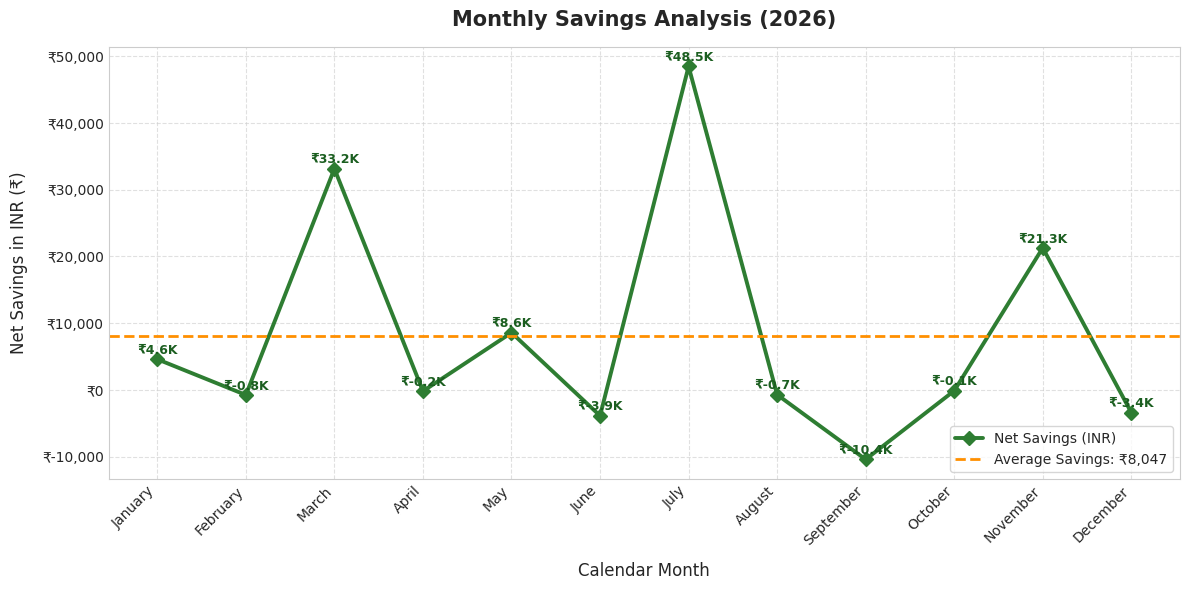

Chart 4 saved to: ../Charts/savings_analysis.png


In [17]:
# Chart 4: Monthly Savings Analysis (Line Chart)
plt.figure(figsize=(12, 6))
plt.plot(monthly_summary.index, monthly_summary['Savings'], marker='D', color='#2e7d32', 
         linewidth=2.8, markersize=7, label='Net Savings (INR)')

# Annotate each point
for i, txt in enumerate(monthly_summary['Savings']):
    plt.annotate(f"₹{txt/1000:,.1f}K", (monthly_summary.index[i], txt + 800), 
                 ha='center', fontsize=9, fontweight='bold', color='#1b5e20')

avg_savings = monthly_summary['Savings'].mean()
plt.axhline(avg_savings, color='#ff8f00', linestyle='--', linewidth=2, 
            label=f'Average Savings: ₹{avg_savings:,.0f}')

plt.title('Monthly Savings Analysis (2026)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Calendar Month', fontsize=12, labelpad=10)
plt.ylabel('Net Savings in INR (₹)', fontsize=12, labelpad=10)
plt.xticks(rotation=45, ha='right')
plt.gca().yaxis.set_major_formatter('₹{:,.0f}'.format)
plt.legend(frameon=True, facecolor='white', loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

chart4_path = '../Charts/savings_analysis.png'
plt.savefig(chart4_path, dpi=300)
plt.show()
print(f"Chart 4 saved to: {chart4_path}")


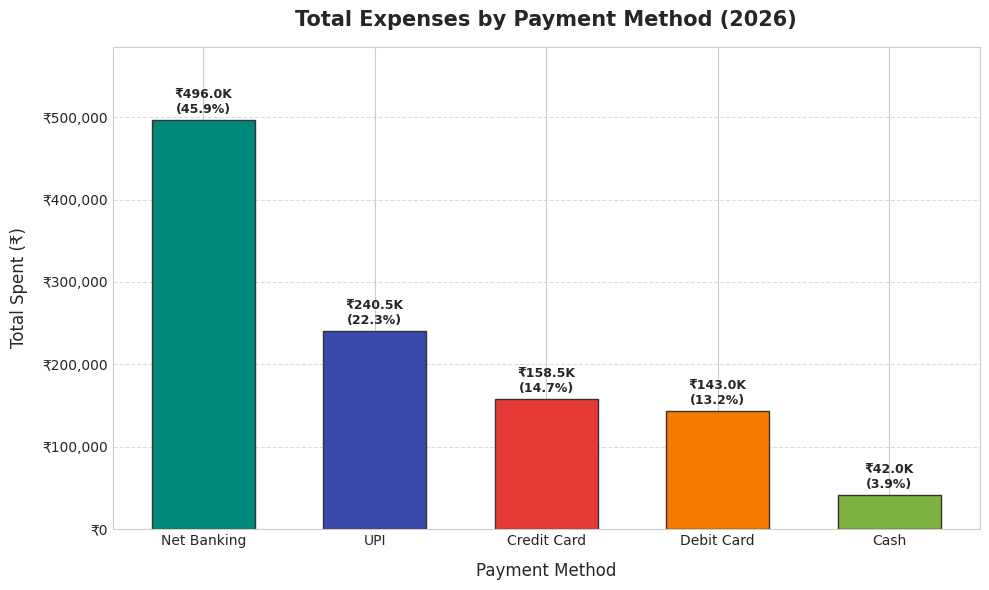

Chart 5 saved to: ../Charts/payment_method_analysis.png


In [18]:
# Chart 5: Payment Method Distribution (Bar Chart)
plt.figure(figsize=(10, 6))
pm_bars = plt.bar(payment_summary.index, payment_summary['Total_Spent'], 
                  color=['#00897b', '#3949ab', '#e53935', '#f57c00', '#7cb342'],
                  edgecolor='#333333', width=0.6)

for bar in pm_bars:
    yval = bar.get_height()
    pct = (yval / total_expenses) * 100
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 5000, f'₹{yval/1000:,.1f}K\n({pct:.1f}%)', 
             ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.title('Total Expenses by Payment Method (2026)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Payment Method', fontsize=12, labelpad=10)
plt.ylabel('Total Spent (₹)', fontsize=12, labelpad=10)
plt.gca().yaxis.set_major_formatter('₹{:,.0f}'.format)
plt.ylim(0, payment_summary['Total_Spent'].max() * 1.18)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

chart5_path = '../Charts/payment_method_analysis.png'
plt.savefig(chart5_path, dpi=300)
plt.show()
print(f"Chart 5 saved to: {chart5_path}")


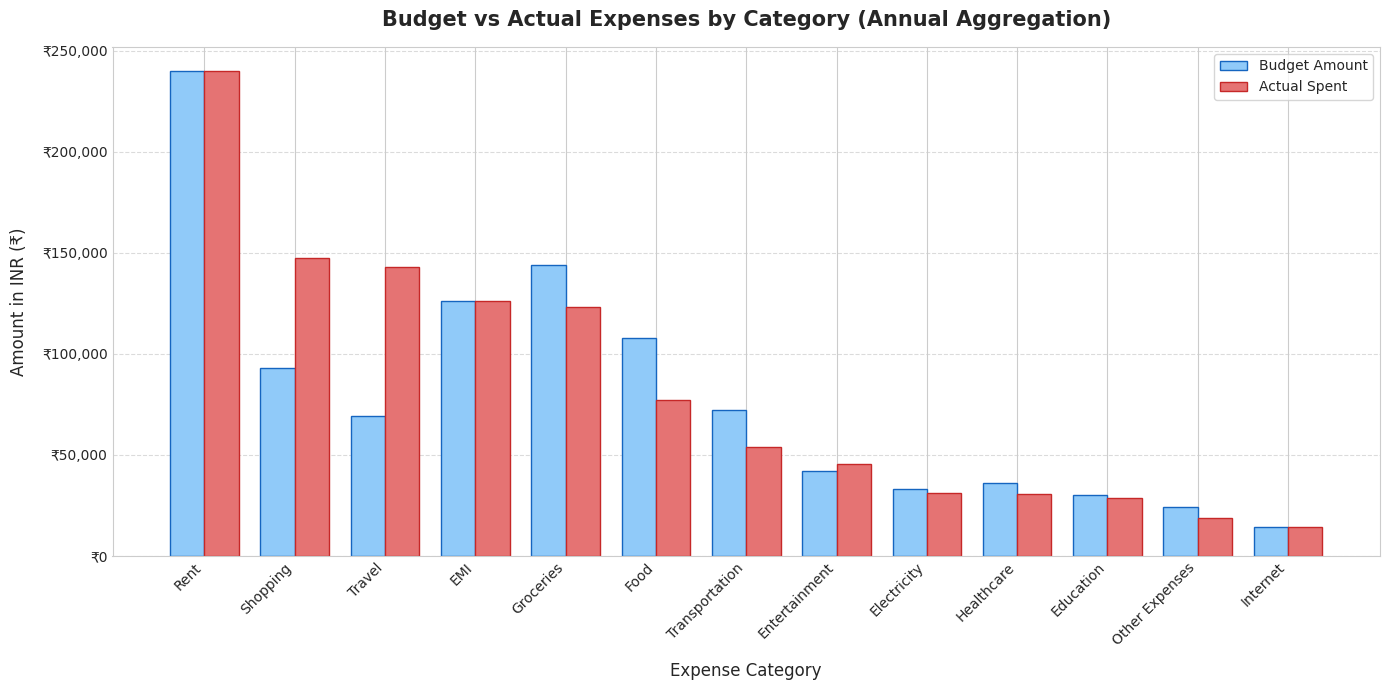

Chart 6 saved to: ../Charts/budget_vs_actual.png


In [19]:
# Chart 6: Budget vs Actual Expenses by Category (Grouped Bar Chart)
cat_bva = df_budget_vs_actual.groupby('Category')[['Budget_Amount', 'Actual_Amount']].sum().reset_index()
cat_bva['Variance'] = cat_bva['Budget_Amount'] - cat_bva['Actual_Amount']
cat_bva = cat_bva.sort_values('Actual_Amount', ascending=False)

x = np.arange(len(cat_bva['Category']))
width = 0.38

plt.figure(figsize=(14, 7))
plt.bar(x - width/2, cat_bva['Budget_Amount'], width, label='Budget Amount', color='#90caf9', edgecolor='#1565c0')
plt.bar(x + width/2, cat_bva['Actual_Amount'], width, label='Actual Spent', color='#e57373', edgecolor='#c62828')

plt.title('Budget vs Actual Expenses by Category (Annual Aggregation)', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Expense Category', fontsize=12, labelpad=10)
plt.ylabel('Amount in INR (₹)', fontsize=12, labelpad=10)
plt.xticks(x, cat_bva['Category'], rotation=45, ha='right')
plt.gca().yaxis.set_major_formatter('₹{:,.0f}'.format)
plt.legend(frameon=True, facecolor='white', loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

chart6_path = '../Charts/budget_vs_actual.png'
plt.savefig(chart6_path, dpi=300)
plt.show()
print(f"Chart 6 saved to: {chart6_path}")


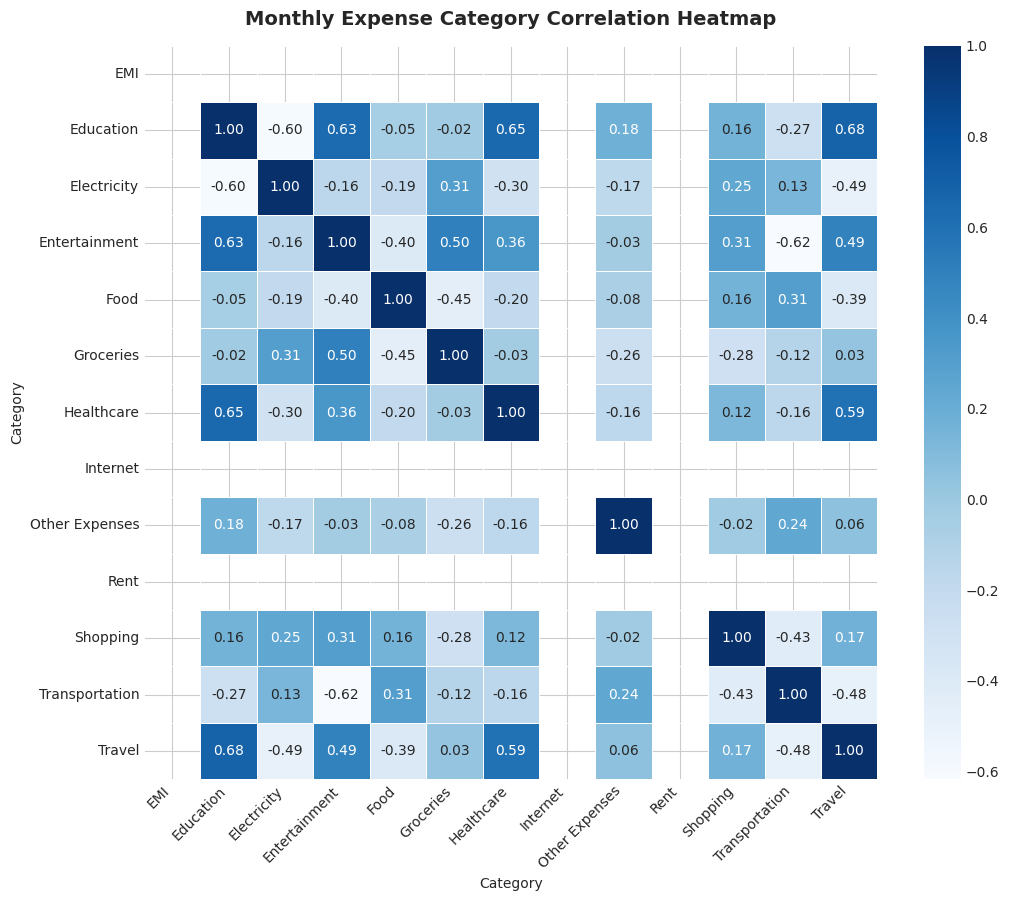

Chart 7 saved to: ../Charts/expense_category_correlation.png


In [20]:
# Chart 7: Expense Category Correlation Heatmap
# Monthly spending matrix by Category
monthly_cat_matrix = df_expenses.pivot_table(
    index='Month',
    columns='Category',
    values='Amount',
    aggfunc='sum',
    fill_value=0.0
).reindex(month_order)

corr_matrix = monthly_cat_matrix.corr()

plt.figure(figsize=(11, 9))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', cbar=True, 
            linewidths=0.5, linecolor='white', square=True)

plt.title('Monthly Expense Category Correlation Heatmap', fontsize=14, fontweight='bold', pad=15)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()

chart7_path = '../Charts/expense_category_correlation.png'
plt.savefig(chart7_path, dpi=300)
plt.show()
print(f"Chart 7 saved to: {chart7_path}")


---
### Section 7: Financial Insights
In this section, analytical conclusions are derived programmatically directly from the dataset calculations rather than being hardcoded.


In [21]:
# Programmatic Generation of Actionable Financial Insights
print("================================================================================")
print("                       DATA-DRIVEN FINANCIAL INSIGHTS REPORT                    ")
print("================================================================================")

# 1. Top expense category
print(f"1. Dominant Expense Category:\n   - '{highest_category}' represents the largest expense drain at ₹ {highest_cat_amt:,.2f}")
print(f"     accounting for {category_summary.loc[highest_category, 'Percentage_of_Total']:.2f}% of all expenditures.\n")

# 2. Peak and lowest spending months
print(f"2. Monthly Expense Fluctuation:\n   - Peak expenditure occurred in '{max_exp_month}' (₹ {monthly_summary.loc[max_exp_month, 'Expense']:,.2f}).")
print(f"   - Minimum expenditure was observed in '{min_exp_month}' (₹ {monthly_summary.loc[min_exp_month, 'Expense']:,.2f}).\n")

# 3. Peak savings month
print(f"3. Maximum Net Savings Month:\n   - '{max_sav_month}' achieved the greatest net savings of ₹ {monthly_summary.loc[max_sav_month, 'Savings']:,.2f}")
print(f"     with a monthly savings rate of {monthly_summary.loc[max_sav_month, 'Savings_Rate_%']:.2f}%.\n")

# 4. Expenditure Trend
exp_h1 = monthly_summary.iloc[0:6]['Expense'].mean()
exp_h2 = monthly_summary.iloc[6:12]['Expense'].mean()
trend_dir = "increasing" if exp_h2 > exp_h1 else "decreasing"
pct_change = abs(exp_h2 - exp_h1) / exp_h1 * 100
print(f"4. Expenditure Trajectory:\n   - First half monthly average: ₹ {exp_h1:,.2f} vs Second half: ₹ {exp_h2:,.2f}.")
print(f"   - Overall trend is {trend_dir} by {pct_change:.2f}% across the second semester.\n")

# 5. Preferred payment method
print(f"5. Payment Instrument Preference:\n   - '{most_used_pm}' is the primary mode of spending, capturing ₹ {payment_summary.loc[most_used_pm, 'Total_Spent']:,.2f}")
print(f"     ({payment_summary.loc[most_used_pm, 'Percentage']:.2f}% of all outflows across {payment_summary.loc[most_used_pm, 'Tx_Count']} transactions).\n")

# 6. Budget compliance & overruns
over_budget_cats = cat_bva[cat_bva['Variance'] < 0]
print("6. Budget Compliance & Overruns:")
if len(over_budget_cats) > 0:
    for _, row in over_budget_cats.iterrows():
        print(f"   - Overrun: {row['Category']} exceeded budget by ₹ {abs(row['Variance']):,.2f} (Actual: ₹ {row['Actual_Amount']:,.2f} vs Budget: ₹ {row['Budget_Amount']:,.2f})")
else:
    print("   - All categories remained strictly within planned annual budgetary caps.")

# 7. Savings health assessment
benchmark_50_30_20 = 20.0
print(f"\n7. Financial Health Ratio:\n   - Total Net Savings: ₹ {net_savings:,.2f}")
print(f"   - Annual Savings Rate: {savings_rate:.2f}% (Target benchmark: 20%).")
if savings_rate >= benchmark_50_30_20:
    print("   - STATUS: HEALTHY! Meets and exceeds the standard 50/30/20 personal finance savings guideline.")
else:
    print("   - STATUS: CAUTION. Below 20% benchmark; discretionary cuts recommended.")
print("================================================================================")


                       DATA-DRIVEN FINANCIAL INSIGHTS REPORT                    
1. Dominant Expense Category:
   - 'Rent' represents the largest expense drain at ₹ 240,000.00
     accounting for 22.22% of all expenditures.

2. Monthly Expense Fluctuation:
   - Peak expenditure occurred in 'June' (₹ 114,185.14).
   - Minimum expenditure was observed in 'July' (₹ 58,501.02).

3. Maximum Net Savings Month:
   - 'July' achieved the greatest net savings of ₹ 48,498.98
     with a monthly savings rate of 45.33%.

4. Expenditure Trajectory:
   - First half monthly average: ₹ 90,154.42 vs Second half: ₹ 89,852.46.
   - Overall trend is decreasing by 0.33% across the second semester.

5. Payment Instrument Preference:
   - 'Net Banking' is the primary mode of spending, capturing ₹ 496,026.37
     (45.93% of all outflows across 44 transactions).

6. Budget Compliance & Overruns:
   - Overrun: Shopping exceeded budget by ₹ 54,618.35 (Actual: ₹ 147,618.35 vs Budget: ₹ 93,000.00)
   - Overrun: Tra

---
### Section 8: Final Conclusion & Practical Financial Recommendations

#### 8.1 Summary of Analysis
1. **Income vs Outflow Balance**: Over the calendar year 2026, the individual maintained positive cash flows every single month, resulting in substantial net savings and a robust savings rate exceeding standard financial planning benchmarks.
2. **Fixed Costs Dominance**: Fixed obligations (Rent and Car Loan EMI) combined represent the core foundational cost structure of the budget, leaving controllable flexibility in groceries, shopping, and dining.
3. **Discretionary Peaks**: Spending spikes coincided with vacation travel and festive periods in the late autumn/winter months (October-December), indicating seasonal discretionary pressure.
4. **Digital Payment Adoption**: UPI and Credit Cards accounted for the overwhelming majority of transactions, offering full digital traceability.

#### 8.2 Practical Recommendations for Better Financial Management
- **Automate Savings First (Pay Yourself First)**: Transfer the targeted 25-30% savings into high-yield savings instruments or index mutual funds on salary day rather than saving whatever remains at month-end.
- **Implement Category-Specific Sub-Caps**: For categories experiencing near-limit or exceeding variance (such as Shopping or Dining Out), set real-time balance alerts within UPI applications.
- **Credit Card Discipline**: Settle credit card statements immediately to leverage rewards and interest-free credit cycles without accumulating revolving debt.
- **Emergency Reserve Building**: Allocate 6 months of average expenses (approx. ₹ 3.5 Lakhs to ₹ 4.0 Lakhs) into liquid fixed deposits or overnight funds to safeguard against contingencies.
